# Bank Marketing Analysis 

### Exploratory Data Analysis

**Dataset:** [Bank Marketing Dataset - Kaggle]("https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset")  
**Tool:** Python (pandas, plotnine, seaborn, matplotlib)  


In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import janitor

import importlib
from scripts.eda import *
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

In [2]:
bank = pd.read_csv('../data/processed/bank_processed.csv')

# Also import version with metadata intact
bank2 = pd.read_parquet('../data/processed/bank_metadata.parquet')

In [3]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,deposit,was_previously_contacted,days_since_last_contact,age_group,campaign_bucket,balance_tier
0,31,blue-collar,single,unknown,1,17,1,0,cellular,6,...,1,-1,0,unknown,0,False,NaN,26-35,1,Low (0-1k)
1,22,student,single,unknown,0,1,0,0,telephone,15,...,4,-1,0,unknown,0,False,NaN,18-25,4-6,Low (0-1k)
2,21,student,single,unknown,0,200,0,0,unknown,1,...,1,-1,0,unknown,0,False,NaN,18-25,1,Low (0-1k)
3,41,self-employed,single,unknown,0,426,1,0,unknown,19,...,1,-1,0,unknown,0,False,NaN,36-45,1,Low (0-1k)
4,24,student,single,unknown,0,782,0,0,cellular,4,...,7,91,1,other,0,True,91.0,18-25,7+,Low (0-1k)


### Campaign Performance and ROI  
Did this work at all?

**What % of customers contacted actually subscribed to a term deposit?**

In [4]:
performance_summary = pd.DataFrame({
    'total_customers': [len(bank)],
    'total_subscribed': [bank['deposit'].sum()],
    'conversion_rate_%': [bank['deposit'].mean() * 100]
})
performance_summary

,total_customers,total_subscribed,conversion_rate_%
0,11162,5289,47.383981


**Did customers who had a successful outcome in a previous campaign convert at a higher rate this time?**


In [5]:
outcome = bank2.groupby('poutcome')['deposit'].agg(conversion_rate='mean', customers='count').reset_index().round(2)
outcome

,poutcome,conversion_rate,customers
0,failure,0.50,1228
1,other,0.57,537
2,success,0.91,1071
3,unknown,0.41,8326


In [6]:
outcome_long = outcome.melt( id_vars='poutcome', value_vars=['conversion_rate', 'customers'],
    var_name='metric',value_name='value')
outcome_long

,poutcome,metric,value
0,failure,conversion_rate,0.50
1,other,conversion_rate,0.57
2,success,conversion_rate,0.91
3,unknown,conversion_rate,0.41
4,failure,customers,1228.00
5,other,customers,537.00
6,success,customers,1071.00
7,unknown,customers,8326.00


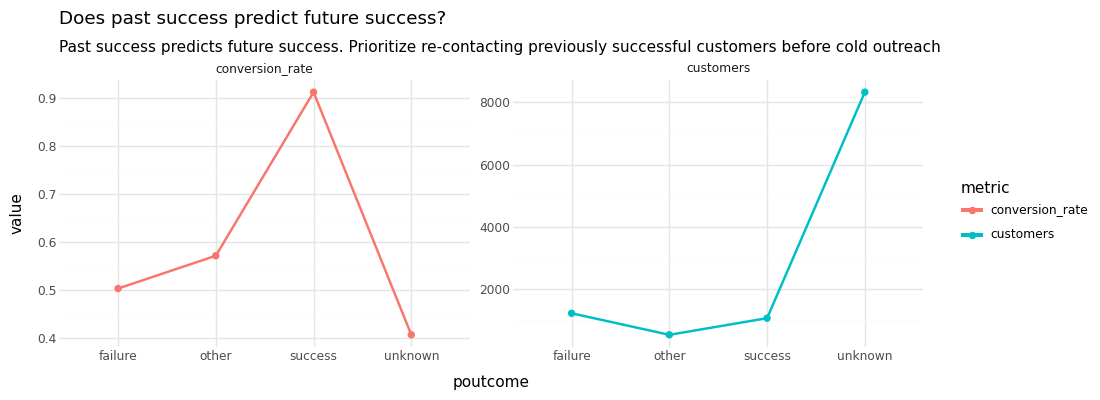

In [7]:
plot_line_grouped(outcome_long, 'poutcome', 'value', 'metric', 
    title='Does past success predict future success?', 
    subtitle='Past success predicts future success. Prioritize re-contacting previously successful customers before cold outreach',
    facet_by='metric', free_scales=True, show_points=True, x_label_angle=0,
    figure_size=(12, 5))

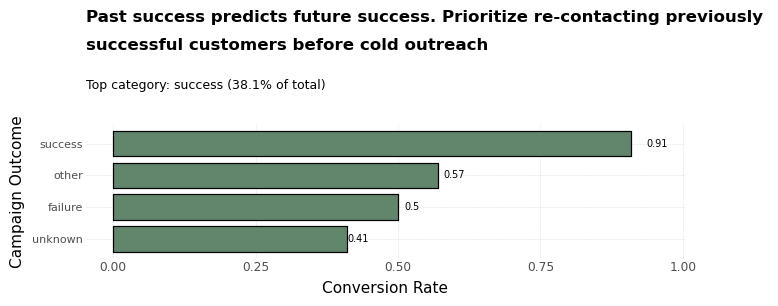

In [40]:
plot_bar(outcome, 'poutcome', 'conversion_rate', show_values=True, bar_width=0.8, 
  title='Past success predicts future success. Prioritize re-contacting previously \n\nsuccessful customers before cold outreach',top_n=None, flip=True,
  value_size=7,
  x_label='Campaign Outcome', y_label='Conversion Rate',
  figure_size=(7,3))

In [ ]:
#from plotnine import ggplot, aes, geom_line, geom_point, facet_wrap, theme_minimal, labs, theme

#(
  #  ggplot(outcome_long, aes(x='poutcome', y='value', group='metric', color='metric'))
 #   + geom_line(size=1)
 #   + geom_point(size=2)
 #   + facet_wrap('metric', scales='free_y')
#    + labs(
 #       title='Conversion Rate and Customer Volume by Previous Outcome',
#        x='Previous Outcome',
#        y=''
#    )
#    + theme_minimal()
 #   + theme(figure_size=(12, 4)))

**Is there a point where additional contact attempts stop helping or start hurting conversion?**

In [ ]:
conversion_attempt = bank.groupby('campaign_bucket', observed=True)['deposit'].agg(conversion_rate='mean', customers='count').reset_index().round(2)
conversion_attempt

,campaign_bucket,conversion_rate,customers
0,1,0.53,4798
1,2-3,0.46,4349
2,4-6,0.39,1414
3,7+,0.27,601


In [ ]:
conversion_long = conversion_attempt.melt( id_vars='campaign_bucket', value_vars=['conversion_rate', 'customers'],
    var_name='metric',value_name='value')
conversion_long

,campaign_bucket,metric,value
0,1,conversion_rate,0.53
1,2-3,conversion_rate,0.46
2,4-6,conversion_rate,0.39
3,7+,conversion_rate,0.27
4,1,customers,4798.00
5,2-3,customers,4349.00
6,4-6,customers,1414.00
7,7+,customers,601.00


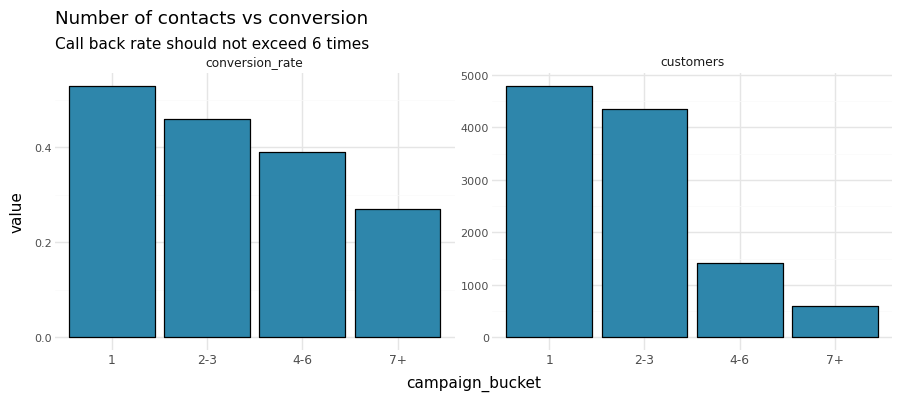

In [ ]:
plot_bar(conversion_long, 'campaign_bucket', 'value',  
          title='Number of contacts vs conversion', 
          subtitle='Call back rate should not exceed 6 times',
          facet_by='metric',  figure_size=(9, 4), flip=False)

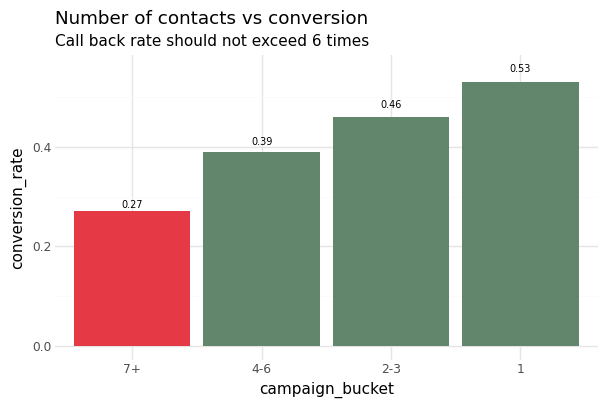

In [ ]:
 plot_highlight_bar(conversion_attempt, 'campaign_bucket', 'conversion_rate', highlight='bottom', normal_color='#62866c', bottom_color='#E63946',
                       title='Number of contacts vs conversion', subtitle='Call back rate should not exceed 6 times',
                       flip=False, show_values=True, value_size=7, figure_size=(6,4))

### Customer Targeting And Segmentation

once we know how it works, who should we actually be calling?

**Which job categories are most likely to subscribe?**

In [ ]:
job = bank.groupby('job', observed=True)['deposit'].agg(
  conversion_rate='mean', customers='count'
).sort_values('conversion_rate', ascending = False).reset_index().round(2)
job

,job,conversion_rate,customers
0,student,0.75,360
1,retired,0.66,778
2,unemployed,0.57,357
3,management,0.51,2566
4,unknown,0.49,70
5,admin.,0.47,1334
6,self-employed,0.46,405
7,technician,0.46,1823
8,services,0.40,923
9,housemaid,0.40,274


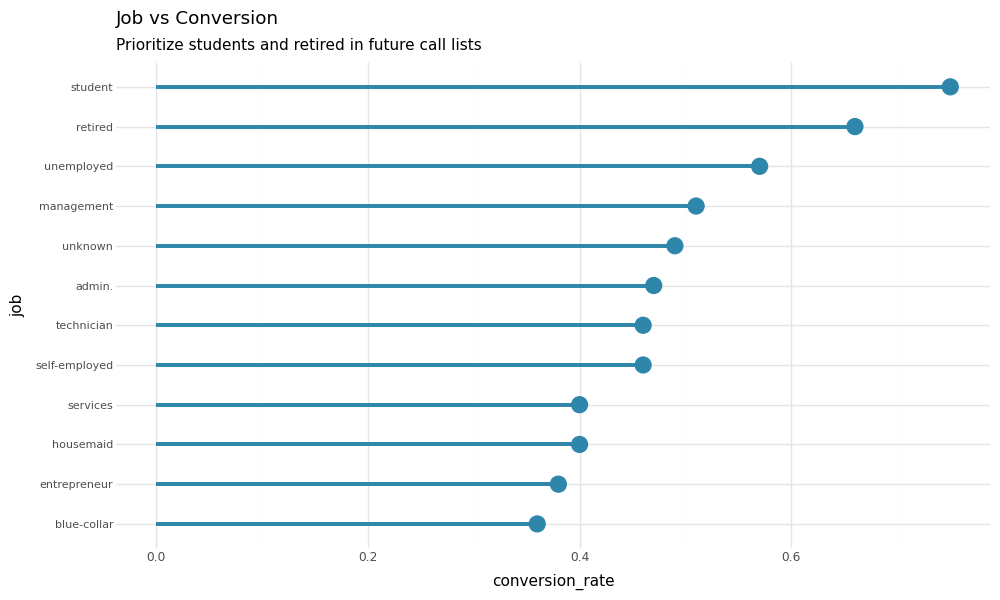

In [ ]:
plot_lollipop(job, 'job', 'conversion_rate', 
              title='Job vs Conversion', 
              subtitle='Prioritize students and retired in future call lists', 
              line_size = 1.6, point_size = 6, show_values=False)

**Which age groups convert best and are younger or older customers being under-targetted?**

In [ ]:
age = bank.groupby('age_group', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
age

,age_group,conversion_rate,customers
0,18-25,0.71,450
1,26-35,0.48,3921
2,36-45,0.41,3158
3,46-55,0.42,2149
4,56-65,0.54,1086
5,66+,0.80,398


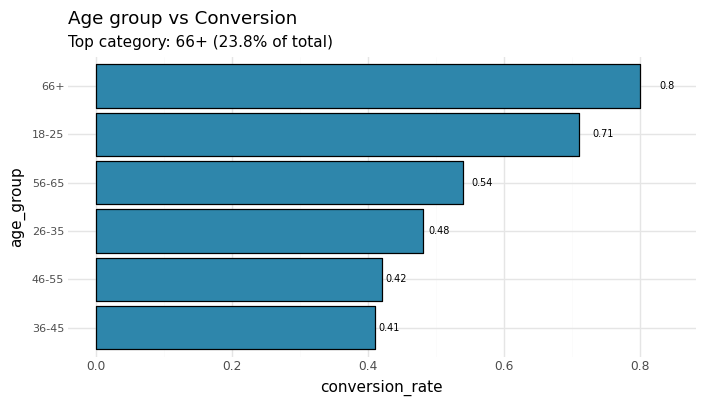

In [ ]:
plot_bar(age, 'age_group', 'conversion_rate', title='Age group vs Conversion', show_values=True, figure_size=(7,4))

**Does education level relate to subscription likelihood?**

In [ ]:
education = bank2.groupby('education', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
education

,education,conversion_rate,customers
0,unknown,0.51,497
1,primary,0.39,1500
2,secondary,0.45,5476
3,tertiary,0.54,3689


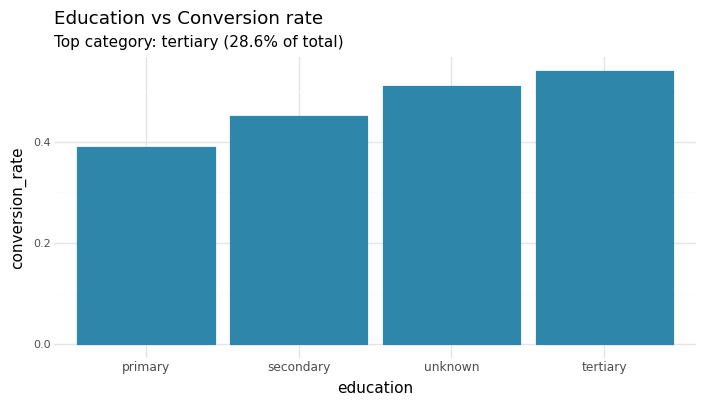

In [ ]:
plot_bar(education, 'education', 'conversion_rate', title='Education vs Conversion rate', subtitle=None,
                  top_n=None, color=DEFAULT_COLOR, flip=False,
                  show_values=False, value_size=7,
                  figure_size=(7, 4))

**Are married, single or divorced customers more likely to subscribe?**

In [ ]:
marital = bank2.groupby('marital', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
marital

,marital,conversion_rate,customers
0,divorced,0.48,1293
1,married,0.43,6351
2,single,0.54,3518


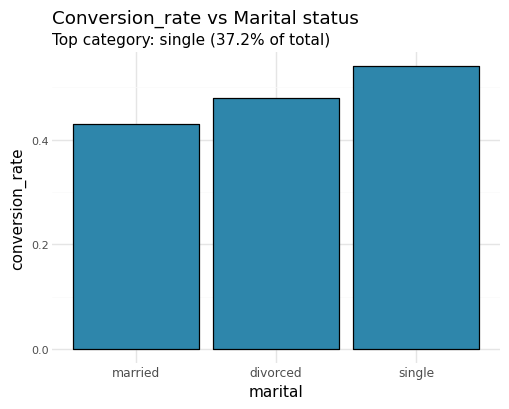

In [ ]:
plot_bar(marital, 'marital', 'conversion_rate', title='Conversion_rate vs Marital status', subtitle=None,
               top_n=None,  figure_size=(5, 4), flip=False)

**Do customers with a negative account balance(overdrawn) behave differently from those with healthy balances?**

In [ ]:
balance = bank.groupby('balance_tier', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
balance

,balance_tier,conversion_rate,customers
0,High (5k+),0.57,771
1,Low (0-1k),0.45,5659
2,Medium (1k-5k),0.55,3270
3,Negative,0.34,1462


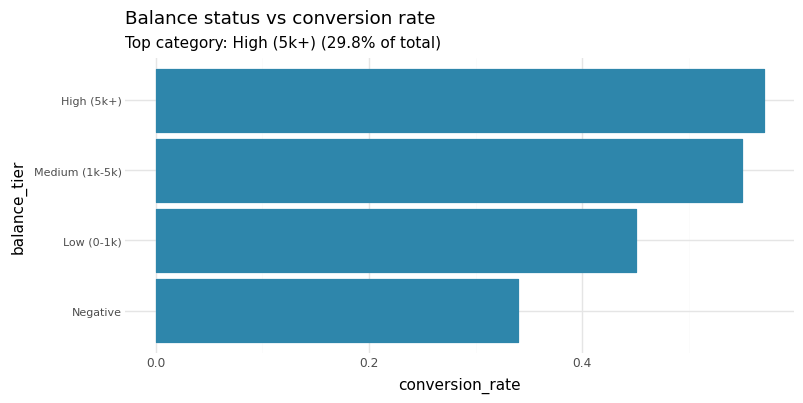

In [ ]:
plot_bar(balance, 'balance_tier', y_col='conversion_rate', title='Balance status vs conversion rate ', subtitle=None,
                  top_n=None, color=DEFAULT_COLOR, flip=True,
                  show_values=False, value_size=7,
                  figure_size=(8, 4))

### Timing And Outreach Strategy   
once we know who to call, when should we call them?

**Which months have been the highest conversion rates?**

In [ ]:
month = bank2.groupby('month', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
month

,month,conversion_rate,customers
0,jan,0.41,344
1,feb,0.57,776
2,mar,0.90,276
3,apr,0.63,923
4,may,0.33,2824
5,jun,0.45,1222
6,jul,0.41,1514
7,aug,0.45,1519
8,sep,0.84,319
9,oct,0.82,392


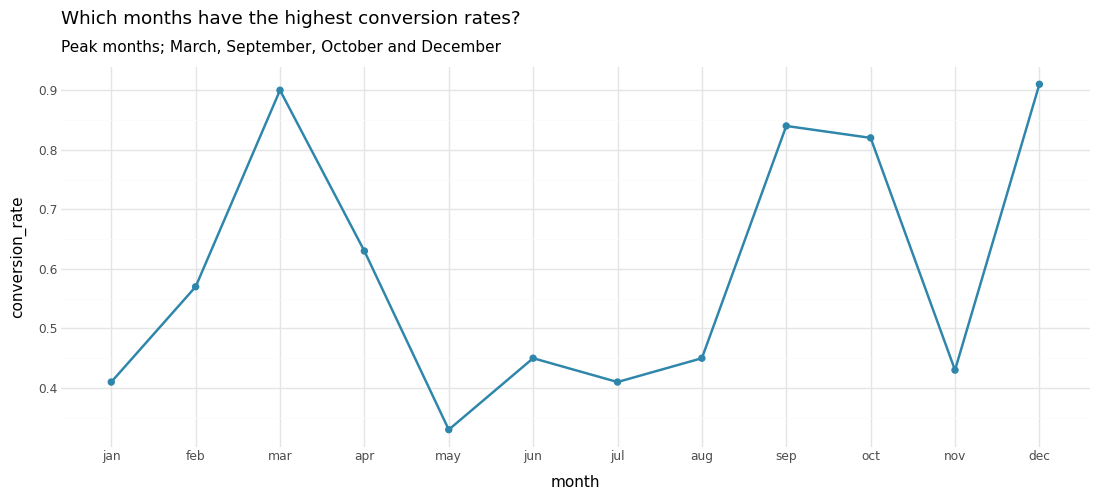

In [ ]:
plot_line(month, 'month', 'conversion_rate',line_size=1,show_points=True, x_label_angle=0,
        title='Which months have the highest conversion rates?', 
        subtitle='Peak months; March, September, October and December', figure_size=(12,6))

**Does day of month affect contact success?**

In [ ]:
day = bank.groupby('day', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
day

,day,conversion_rate,customers
0,1,0.74,122
1,2,0.54,334
2,3,0.58,306
3,4,0.57,402
4,5,0.45,477
5,6,0.40,447
6,7,0.41,382
7,8,0.48,419
8,9,0.49,364
9,10,0.74,163


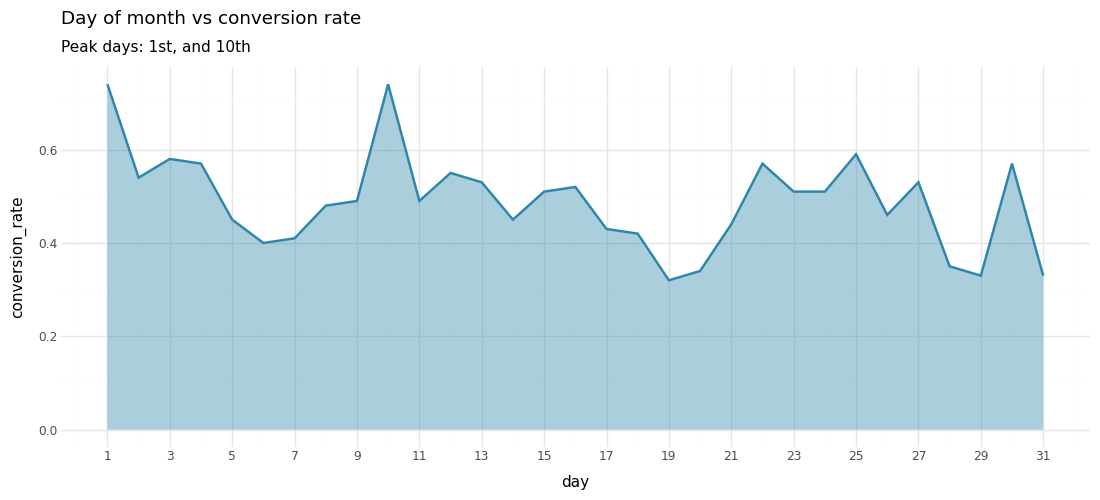

In [ ]:
plot_area(day, 'day', 'conversion_rate', x_breaks = 2, alpha=0.4, 
          title='Day of month vs conversion rate', 
          subtitle='Peak days: 1st, and 10th', line_size=1, show_points=False, figure_size=(12, 6))

**Which contact method works better?**

In [ ]:
contact = bank.groupby('contact', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
contact

,contact,conversion_rate,customers
0,cellular,0.54,8042
1,telephone,0.50,774
2,unknown,0.23,2346


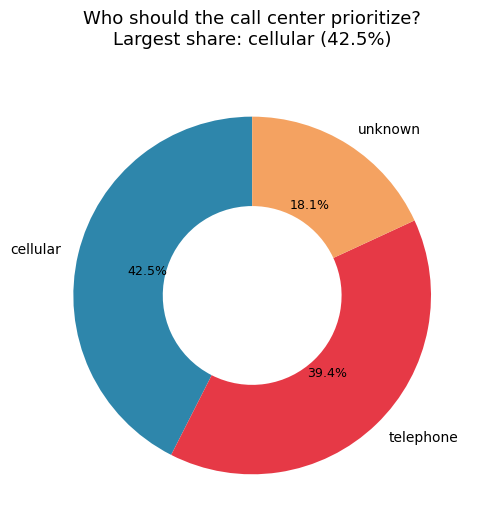

In [ ]:
plot_donut(contact, 'contact', 'conversion_rate', title='Who should the call center prioritize?', subtitle=None,
               top_n=None, colors=None, figsize=(5, 6))

### Financial Risk & Product Fit   
Does someone's existing financial situation affect whether this product ia a fit?

**Do customers with an existing financial situation affect whether this product is a fit?**

In [ ]:
finance = bank.groupby(['housing','loan'])['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)
finance

,housing,loan,conversion_rate,customers
0,0,0,0.60,5256
1,0,1,0.35,625
2,1,0,0.38,4446
3,1,1,0.32,835


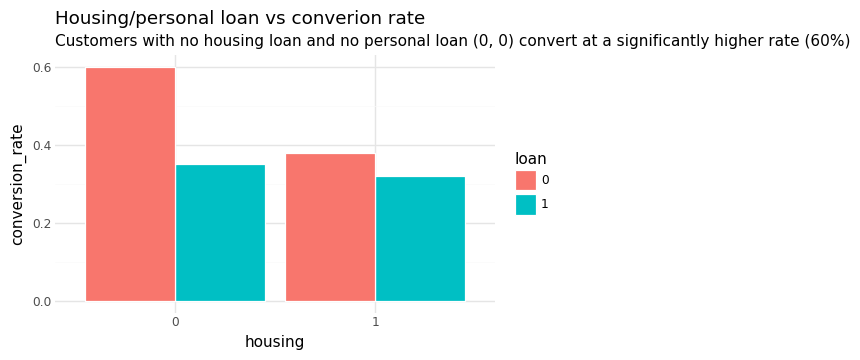

In [ ]:
finance['housing'] = finance['housing'].astype(str)
finance['loan'] = finance['loan'].astype(str)

plot_bar_grouped(finance, 'housing', 'loan', 'conversion_rate', title='Housing/personal loan vs converion rate',
                subtitle='Customers with no housing loan and no personal loan (0, 0) convert at a significantly higher rate (60%)', flip=False, figure_size=(6, 4))

**Are customers with credit in default ever converting and should they be excluded from future campaigns entirely?**

In [ ]:
credit = bank.groupby('default', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)


credit['default'] = credit['default'].replace({1: 'Credit in default', 0:'No credit in default'})
credit

,default,conversion_rate,customers
0,No credit in default,0.48,10994
1,Credit in default,0.31,168


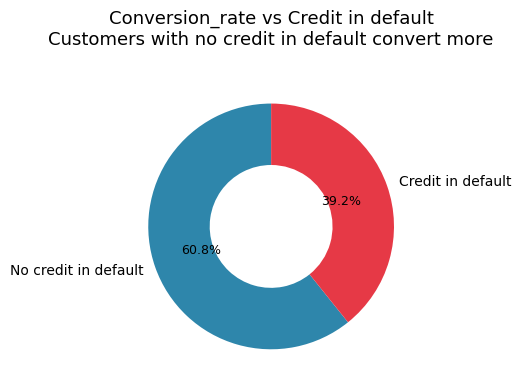

In [ ]:
plot_donut(credit, 'default', 'conversion_rate', 
            title='Conversion_rate vs Credit in default', 
            subtitle='Customers with no credit in default convert more',
            top_n=None, colors=None, figsize=(6, 4))

## Operational & Process 

**How much does having been contacted in a past campaign change this campaign's outcome, vs reaching someone completely cold?** 

In [ ]:
prior_contact = bank.groupby('was_previously_contacted', observed=True)['deposit'].agg(
    conversion_rate='mean', customers='count'
).reset_index().round(2)

prior_contact['was_previously_contacted'] = prior_contact['was_previously_contacted'].replace({True: 'Previously contacted', False:'No prior contact'})

prior_contact

,was_previously_contacted,conversion_rate,customers
0,No prior contact,0.41,8324
1,Previously contacted,0.67,2838


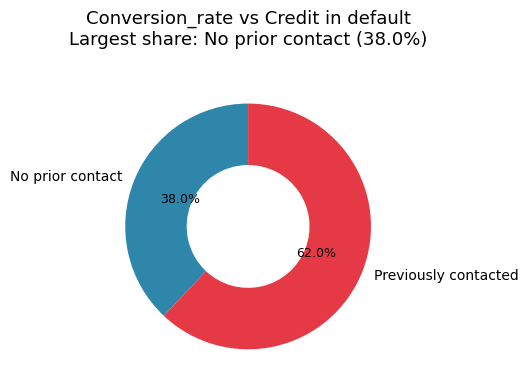

In [ ]:
plot_donut(prior_contact, 'was_previously_contacted', 'conversion_rate', 
          title='Conversion_rate vs Credit in default', 
          top_n=None, colors=None, figsize=(7, 4))

**How long does a typical successful call last, and can call duration data be used to improve real-time coaching for call agents?**

In [ ]:
duration = bank.groupby('deposit')['duration'].agg(
    average_duration_seconds='mean', median_duration_seconds='median', calls='count'
).reset_index()

duration


,deposit,average_duration_seconds,median_duration_seconds,calls
0,0,223.130257,163.0,5873
1,1,537.294574,426.0,5289


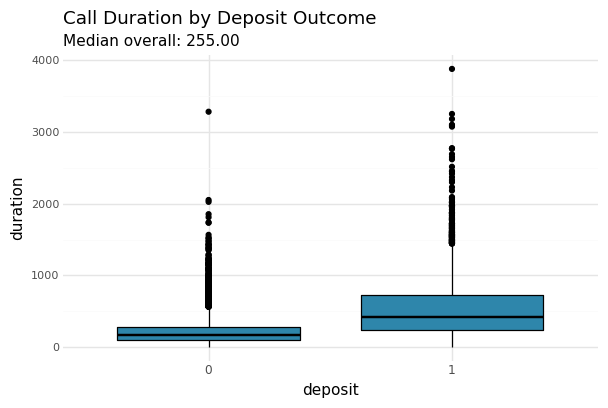

In [ ]:
plot_boxplot(bank.assign(deposit=bank['deposit'].astype(str)), 'duration', 'deposit', flip=False,
             title='Call Duration by Deposit Outcome', figure_size=(6, 4))